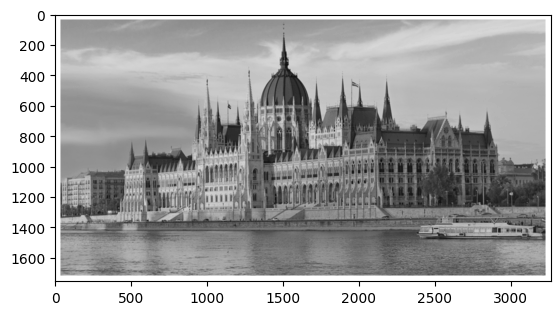

In [15]:
import cv2, matplotlib.pyplot as plt, numpy as np
from PIL import Image 
img = Image.open("image1.png")
img = np.array(img.convert('L'))

plt.imshow(img, cmap= "gray")

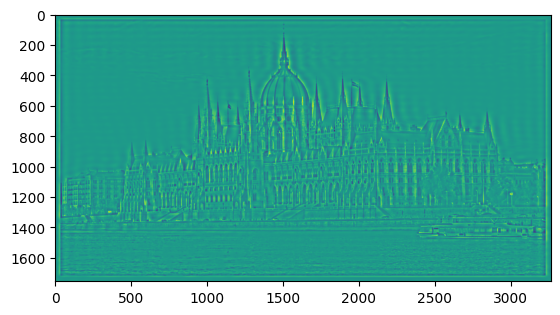

In [27]:
row, col = img.shape
center_row, center_col = row // 2, col // 2

low_cutoff = 40

high_cutoff = 1000

fft_img = np.fft.fft2(img)
fft_shift = np.fft.fftshift(fft_img)

# Creating a fourier mask
x = np.arange(col) - center_col
y = np.arange(row) - center_row
X, Y = np.meshgrid(x, y)

 # Calculate distance from the center for every pixel
distance = np.sqrt(X**2 + Y**2)

# We preserve the area BETWEEN low_cutoff and high_cutoff (creating a ring mask)
mask = (distance >= low_cutoff) & (distance <= high_cutoff)

fft_filt = fft_shift * mask

# Undo the central shift
fft_ishift = np.fft.ifftshift(fft_filt)
img_filt_compl = np.fft.ifft2(fft_ishift)

# The image must be real, so we take the real part
img_filt = np.real(img_filt_compl)

plt.imshow(img_filt)

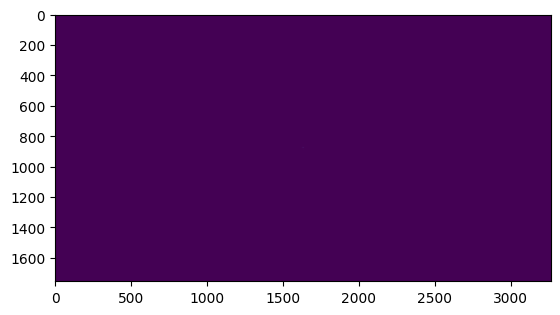

In [8]:
# Transformada de Fourier
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)

potencia = np.abs(fshift)

plt.imshow(potencia)

FILTROS DE GABOR